In [10]:

!pip install -q kaggle nltk

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import pickle
import tensorflow as tf

from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

nltk.download('stopwords')

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [11]:
!pip install -q kagglehub

In [12]:
import kagglehub
import os
import pandas as pd

path = kagglehub.dataset_download("snap/amazon-fine-food-reviews")

print("Dataset path:", path)
print("Files:", os.listdir(path))

Using Colab cache for faster access to the 'amazon-fine-food-reviews' dataset.
Dataset path: /kaggle/input/amazon-fine-food-reviews
Files: ['hashes.txt', 'Reviews.csv', 'database.sqlite']


In [13]:
df = pd.read_csv('Reviews.csv')

print("Dataset shape:", df.shape)

df.head()


Dataset shape: (568454, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB


In [15]:

df.describe().T


,count,mean,std,min,25%,50%,75%,max
Id,568454.0,2.842275e+05,1.640987e+05,1.0,1.421142e+05,2.842275e+05,4.263408e+05,5.684540e+05
HelpfulnessNumerator,568454.0,1.743817e+00,7.636513e+00,0.0,0.000000e+00,0.000000e+00,2.000000e+00,8.660000e+02
HelpfulnessDenominator,568454.0,2.228810e+00,8.289740e+00,0.0,0.000000e+00,1.000000e+00,2.000000e+00,9.230000e+02
Score,568454.0,4.183199e+00,1.310436e+00,1.0,4.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00
Time,568454.0,1.296257e+09,4.804331e+07,939340800.0,1.271290e+09,1.311120e+09,1.332720e+09,1.351210e+09


In [16]:

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique values:")
print(df.nunique())


Missing values:
Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

Duplicate rows: 0

Unique values:
Id                        568454
ProductId                  74258
UserId                    256059
ProfileName               218415
HelpfulnessNumerator         231
HelpfulnessDenominator       234
Score                          5
Time                        3168
Summary                   295742
Text                      393579
dtype: int64


In [17]:

new_df = df[['Text', 'Score']].copy()

print("Original shape:", new_df.shape)
print("Duplicates:", new_df.duplicated().sum())

new_df = new_df.dropna(subset=['Text', 'Score'])
new_df = new_df.drop_duplicates().reset_index(drop=True)

print("After removing duplicates:", new_df.shape)

new_df.head()


Original shape: (568454, 2)
Duplicates: 174779
After removing duplicates: (393675, 2)


,Text,Score
0,I have bought several of the Vitality canned d...,5
1,Product arrived labeled as Jumbo Salted Peanut...,1
2,This is a confection that has been around a fe...,4
3,If you are looking for the secret ingredient i...,2
4,Great taffy at a great price. There was a wid...,5


Score
1     36280
2     20804
3     29772
4     56074
5    250745
Name: count, dtype: int64


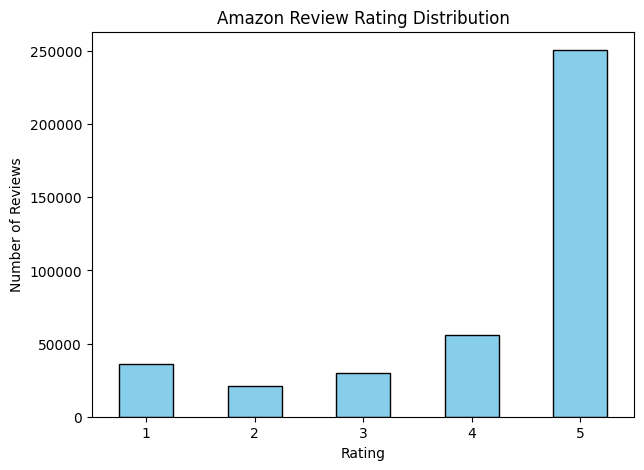

In [18]:

print(new_df['Score'].value_counts().sort_index())

plt.figure(figsize=(7, 5))

new_df['Score'].value_counts().sort_index().plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)

plt.title('Amazon Review Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.show()


count    393675.000000
mean        433.899610
std         433.084754
min          12.000000
25%         181.000000
50%         304.000000
75%         527.000000
max       21409.000000
Name: review_length, dtype: float64


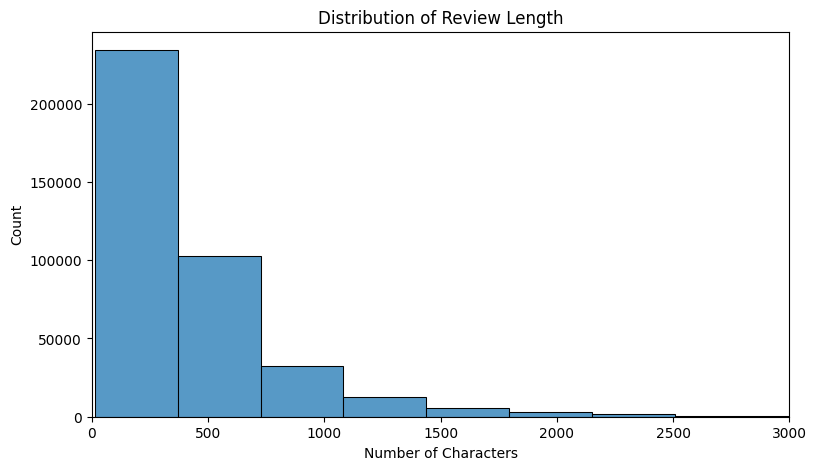

In [19]:

new_df['review_length'] = new_df['Text'].str.len()

print(new_df['review_length'].describe())

plt.figure(figsize=(9, 5))
sns.histplot(new_df['review_length'], bins=60)
plt.xlim(0, 3000)
plt.title('Distribution of Review Length')
plt.xlabel('Number of Characters')
plt.show()


In [20]:

new_df = new_df[new_df['Score'] != 3].copy()

def categorical_score(Score):
    if Score > 3:
        return 1
    else:
        return 0

new_df['Score'] = new_df['Score'].apply(categorical_score)

new_df = new_df.reset_index(drop=True)

print("Dataset shape:", new_df.shape)
print(new_df['Score'].value_counts())

new_df.head()


Dataset shape: (363903, 3)
Score
1    306819
0     57084
Name: count, dtype: int64


,Text,Score,review_length
0,I have bought several of the Vitality canned d...,1,263
1,Product arrived labeled as Jumbo Salted Peanut...,0,190
2,This is a confection that has been around a fe...,1,509
3,If you are looking for the secret ingredient i...,0,219
4,Great taffy at a great price. There was a wid...,1,140


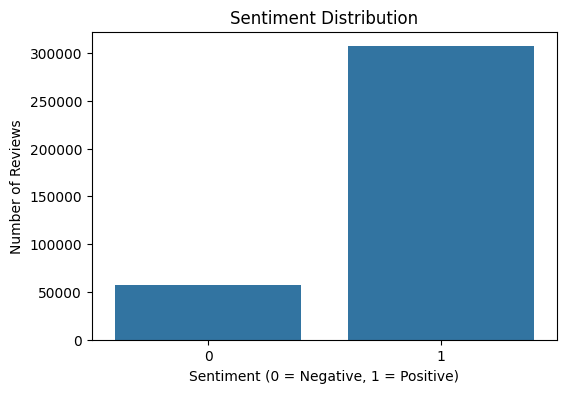

Score
1    84.313402
0    15.686598
Name: proportion, dtype: float64


In [21]:

plt.figure(figsize=(6, 4))

sns.countplot(data=new_df, x='Score')

plt.title('Sentiment Distribution')
plt.xlabel('Sentiment (0 = Negative, 1 = Positive)')
plt.ylabel('Number of Reviews')
plt.show()

print(new_df['Score'].value_counts(normalize=True) * 100)


In [22]:
###  Split dataset into train validation test dataset

X = new_df['Text']
y = new_df['Score']

X_train, X_temp, Y_train, Y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp, Y_temp,
    test_size=0.50,
    random_state=42,
    stratify=Y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


Training: (254732,)
Validation: (54585,)
Testing: (54586,)


In [23]:

def Preprocessing(text):
    text = str(text).lower()

    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)

    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\n', ' ', text)
    text = re.sub(r'\w*\d\w*', '', text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text

print(Preprocessing(
    "This product isn't good! <br> Visit https://example.com"
))


this product is not good visit


In [25]:
#### removing stopwords...

stop_words = set(stopwords.words('english'))

negation_words = {'no', 'not', 'nor', 'never'}
stop_words = stop_words - negation_words

def remove_stopwords(text):
    text = str(text)
    words = text.split()

    filtered = [
        word for word in words
        if word not in stop_words
    ]

    return " ".join(filtered)

print(remove_stopwords("this product is not good"))


product not good


In [27]:
#### stemming.....


ps = PorterStemmer()

def apply_stemming(text):
    words = text.split()

    stemmed_words = [
        ps.stem(word) for word in words
    ]

    return " ".join(stemmed_words)

text = "I am loving the delicious foods and enjoying the amazing flavors"

print(apply_stemming(text))

i am love the delici food and enjoy the amaz flavor


In [28]:

def clean_review(text):
    text = Preprocessing(text)
    text = remove_stopwords(text)
    text = apply_stemming(text)

    return text

print(clean_review("I am not satisfied with this product!"))


not satisfi product


In [29]:

X_train = X_train.astype(str).apply(clean_review)
X_val = X_val.astype(str).apply(clean_review)
X_test = X_test.astype(str).apply(clean_review)

print(X_train.head())

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


191991    great coffeei tast mani differ brandsthi one r...
318595    like coffe pod bought brand test like best far...
1202      long time classic not sweet honey roast peanut...
210272    white swizzl stix bought part blue white theme...
347986    best k cup coffe tri yet brew ounc one cup rig...
Name: Text, dtype: object

Training samples: 254732
Validation samples: 54585
Testing samples: 54586


In [30]:

from collections import Counter

word_count = Counter()

for sentence in X_train:
    word_count.update(sentence.split())

vocabulary_size = len(word_count)

print("Vocabulary size:", vocabulary_size)
print("Most common words:", word_count.most_common(20))


Vocabulary size: 190250
Most common words: [('not', 264896), ('like', 119142), ('tast', 112209), ('flavor', 87559), ('good', 87336), ('use', 82720), ('product', 81378), ('love', 80338), ('one', 80032), ('great', 74502), ('tri', 71924), ('tea', 64069), ('coffe', 63054), ('get', 59502), ('make', 59183), ('would', 55508), ('food', 52221), ('buy', 47189), ('no', 45807), ('time', 44297)]


In [31]:
### tokenizer
vocab_size = 10000
max_length = 51

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="NA"
)

tokenizer.fit_on_texts(X_train)

train_sequences = tokenizer.texts_to_sequences(X_train)
val_sequences = tokenizer.texts_to_sequences(X_val)
test_sequences = tokenizer.texts_to_sequences(X_test)

print("Original review:", X_train.iloc[0])
print("Token sequence:", train_sequences[0][:30])


Original review: great coffeei tast mani differ brandsthi one rich bold deliciousi highli recommend coffe nice get go blend
Token sequence: [11, 3171, 4, 83, 73, 1, 10, 322, 564, 3915, 179, 49, 14, 72, 15, 40, 196]


In [32]:
#### Padding


X_train_pad = pad_sequences(
    train_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_val_pad = pad_sequences(
    val_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    test_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

Y_train = Y_train.to_numpy()
Y_val = Y_val.to_numpy()
Y_test = Y_test.to_numpy()

print("X_train:", X_train_pad.shape)
print("X_val:", X_val_pad.shape)
print("X_test:", X_test_pad.shape)

print("Y_train:", Y_train.shape)
print("Y_val:", Y_val.shape)
print("Y_test:", Y_test.shape)


X_train: (254732, 51)
X_val: (54585, 51)
X_test: (54586, 51)
Y_train: (254732,)
Y_val: (54585,)
Y_test: (54586,)


In [37]:
##### Building LSTM model

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

tf.keras.backend.clear_session()

embedding_dim = 64

model = Sequential([
    tf.keras.Input(shape=(max_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    LSTM(128, return_sequences=False, use_cudnn=False),

    Dropout(0.4),

    Dense(64, activation='relu'),

    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 51, 64)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 747,137 (2.85 MB)

 Trainable params: 747,137 (2.85 MB)

 Non-trainable params: 0 (0.00 B)

In [38]:
###### Training the model...


early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    Y_train,
    validation_data=(X_val_pad, Y_val),
    epochs=10,
    batch_size=256,
    callbacks=[early_stop],
    verbose=2
)


Epoch 1/10
996/996 - 21s - 21ms/step - accuracy: 0.9095 - loss: 0.2300 - val_accuracy: 0.9198 - val_loss: 0.1985
Epoch 2/10
996/996 - 11s - 11ms/step - accuracy: 0.9282 - loss: 0.1817 - val_accuracy: 0.9266 - val_loss: 0.1848
Epoch 3/10
996/996 - 11s - 11ms/step - accuracy: 0.9400 - loss: 0.1543 - val_accuracy: 0.9304 - val_loss: 0.1835
Epoch 4/10
996/996 - 11s - 11ms/step - accuracy: 0.9494 - loss: 0.1324 - val_accuracy: 0.9276 - val_loss: 0.2042
Epoch 5/10
996/996 - 11s - 11ms/step - accuracy: 0.9571 - loss: 0.1150 - val_accuracy: 0.9242 - val_loss: 0.2223
Epoch 6/10
996/996 - 11s - 11ms/step - accuracy: 0.9628 - loss: 0.1016 - val_accuracy: 0.9215 - val_loss: 0.2429


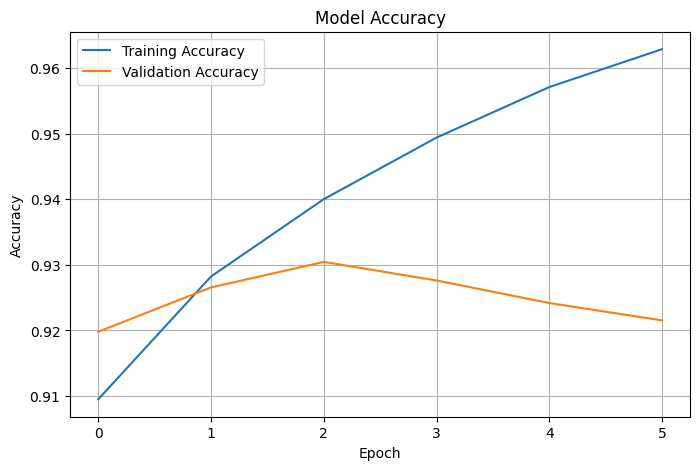

In [39]:
#### Plotting training and validation performance


plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()


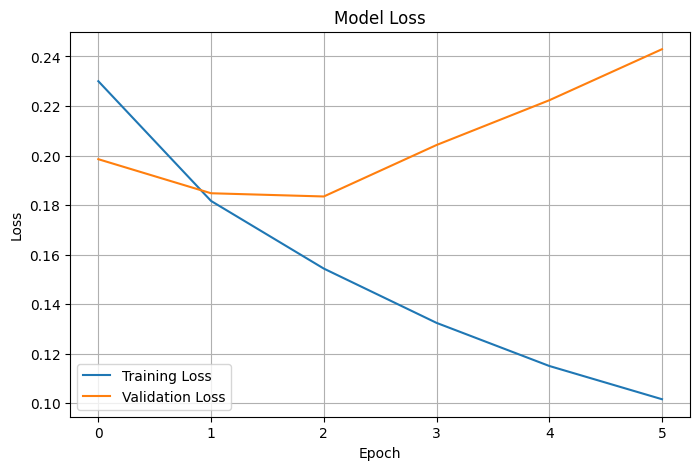

In [40]:

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


In [41]:
##### Evaluating on the test set


test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    Y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


1706/1706 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9294 - loss: 0.1841
Test Loss: 0.18407019972801208
Test Accuracy: 0.9293591976165771


In [42]:

Y_prob = model.predict(X_test_pad).ravel()

Y_pred = (Y_prob >= 0.5).astype(int)

print("Accuracy:", accuracy_score(Y_test, Y_pred))

print("\nClassification Report:")
print(classification_report(
    Y_test,
    Y_pred,
    target_names=['Negative', 'Positive']
))

print("ROC-AUC:", roc_auc_score(Y_test, Y_prob))


1706/1706 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step
Accuracy: 0.9293591763455831

Classification Report:
              precision    recall  f1-score   support

    Negative       0.81      0.72      0.76      8563
    Positive       0.95      0.97      0.96     46023

    accuracy                           0.93     54586
   macro avg       0.88      0.84      0.86     54586
weighted avg       0.93      0.93      0.93     54586

ROC-AUC: 0.9567598188120902


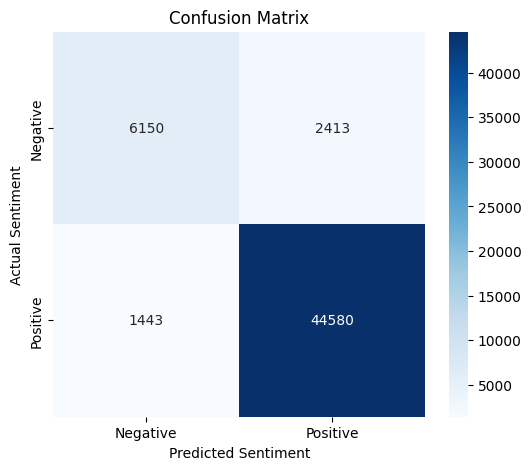

In [43]:
#### confusion matrixx..


cm = confusion_matrix(Y_test, Y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.title('Confusion Matrix')
plt.show()


In [44]:
##### Predicting sentiment for new reviews


def predict_review(review_text, tokenizer, model, maxlen=51):

    review_text = clean_review(review_text)

    sequence = tokenizer.texts_to_sequences([review_text])

    padded = pad_sequences(
        sequence,
        maxlen=maxlen,
        padding='post',
        truncating='post'
    )

    prediction = model.predict(padded, verbose=0)[0][0]

    predicted_class = int(prediction >= 0.5)

    label_map = {
        0: 'Negative',
        1: 'Positive'
    }

    return label_map[predicted_class], float(prediction)


In [45]:
#### Exa 1... negative

new_review = """
Very disappointed. The item was stale and lacked flavor.
The packaging was damaged on arrival.
Would not recommend.
"""

label, probability = predict_review(
    new_review, tokenizer, model
)

print("Sentiment:", label)
print("Positive probability:", probability)


Sentiment: Negative
Positive probability: 0.00029091897886246443


In [46]:
### exa 2 positive...


new_review_2 = """
Absolutely love this product!
The flavor is rich and authentic.
It exceeded my expectations.
Will definitely order again!
"""

label, probability = predict_review(
    new_review_2, tokenizer, model
)

print("Sentiment:", label)
print("Positive probability:", probability)


Sentiment: Positive
Positive probability: 0.9999922513961792


In [47]:
### exa 3 .. mixed review


new_review_3 = """
The taste was decent, but the packaging was poor.
The delivery was fast, although the quality
was not as good as expected.
"""

label, probability = predict_review(
    new_review_3, tokenizer, model
)

print("Sentiment:", label)
print("Positive probability:", probability)


Sentiment: Negative
Positive probability: 0.08641114830970764


In [48]:
#### Saving the model and tokenizer


model.save('sentiment_lstm_model.keras')

with open('tokenizer.pkl', 'wb') as file:
    pickle.dump(tokenizer, file)

print("Model and tokenizer saved successfully!")


Model and tokenizer saved successfully!


In [50]:
##### Saving the preprocessing configuration..


import json

config = {
    "vocab_size": vocab_size,
    "max_length": max_length,
    "embedding_dim": embedding_dim,
    "labels": {
        "0": "Negative",
        "1": "Positive"
    },
    "threshold": 0.5
}

with open('config.json', 'w') as file:
    json.dump(config, file, indent=4)


In [53]:

from sklearn.metrics import precision_score, recall_score, f1_score

results = {
    'test_accuracy': float(accuracy_score(Y_test, Y_pred)),
    'precision_macro': float(precision_score(Y_test, Y_pred, average='macro')),
    'recall_macro': float(recall_score(Y_test, Y_pred, average='macro')),
    'f1_macro': float(f1_score(Y_test, Y_pred, average='macro')),
    'roc_auc': float(roc_auc_score(Y_test, Y_prob))
}

with open('results.json', 'w') as file:
    json.dump(results, file, indent=4)

print(results)


{'test_accuracy': 0.9293591763455831, 'precision_macro': 0.8793042329000755, 'recall_macro': 0.8434261739294711, 'f1_macro': 0.8599359138227687, 'roc_auc': 0.9567598188120902}
